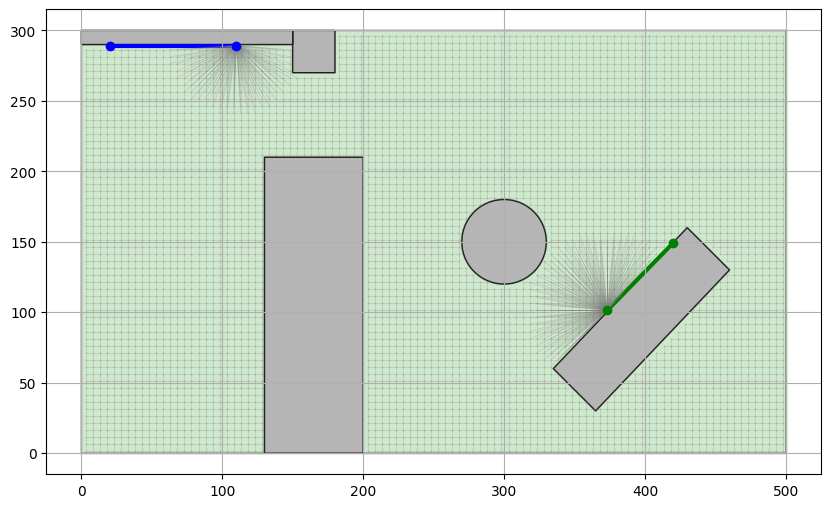

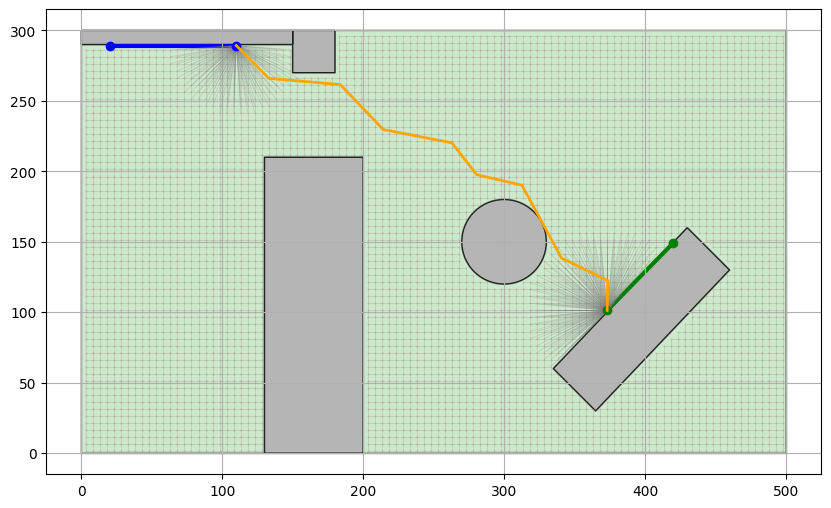

In [8]:
from evo_pathfinding_gen_sm.geometry import Environment, Mount, Grid, Blob
from evo_pathfinding_gen_sm.rendering.renderer import render_environment, render_phenotype, render_genotype, render_genotype_field, render_flow_field
from evo_pathfinding_gen_sm.genetic_algorithm.genetic_code import Phenotype, Genotype
from evo_pathfinding_gen_sm.genetic_algorithm.genetic_processes import mutate_shift, mutate_invert, uniform_crossover

from evo_pathfinding_gen_sm.genetic_algorithm.fitness import find_fitness
from evo_pathfinding_gen_sm.structural_simulator import StructuralSimulator
from evo_pathfinding_gen_sm.pathfinding.grid_pathfinder import GridPathfinder
from evo_pathfinding_gen_sm.pathfinding.prm_pathfinder import PRMPathfinder
import matplotlib.pyplot as plt
import shapely.plotting as plotting
import shapely
import numpy as np
import networkx as nx
import yaml

mount1_plate = shapely.geometry.LineString([(110, 289), (20, 289)])
mount2_plate = shapely.geometry.LineString([(373, 101.5), (420, 149.5)])



env = Environment(
    area=(0, 0, 500, 300),
    obstacles=[
        shapely.geometry.Polygon([ (430, 160),(460, 130), (365, 30), (335, 60)]),
        shapely.geometry.box(0, 300, 150, 290),
        shapely.geometry.box(130, 0, 200, 210),
        shapely.geometry.box(150, 300, 180, 270),
        shapely.geometry.Point(300, 150).buffer(30),


    ],
    mount1=Mount(mount1_plate.coords[0], mount1_plate.coords[1], thickness=0.5),
    mount2=Mount(mount2_plate.coords[0], mount2_plate.coords[1], thickness=0.5),
    thickness=0.5
)
render_environment(env)

start_node = next((n for n, d in env.grid.graph.nodes(data=True) if d.get('start')), None)
target_node = next((n for n, d in env.grid.graph.nodes(data=True) if d.get('target')), None)

pathfinder = PRMPathfinder(env)
pathfinder.build_roadmap(node_count=1000,n = 5000)
path = pathfinder.find_path(start_node, target_node)

while path == []:
    pathfinder.build_roadmap(node_count=1000,n = 400,connection_mode='nearestn')
    path = pathfinder.find_path(start_node, target_node)
render_environment(env,path)